In [ ]:
## import basic library

import os
import geopandas as gpd
import laspy
import numpy as np
import matplotlib.pyplot as plt

from shapely.geometry import box, Point
from shapely.ops import unary_union
from shapely.prepared import prep




In [ ]:
# load underground pipeline data

hal_path = "../data/leitungen/HAL.shp"
vl_path = "../data/leitungen/VL.shp"

hal = gpd.read_file(hal_path)
vl = gpd.read_file(vl_path)

print("HAL CRS:", hal.crs)
print("VL CRS:", vl.crs)

HAL CRS: EPSG:25832
VL CRS: EPSG:25832


In [ ]:
# change cordinates system

target_crs = "EPSG:32632"

hal = hal.to_crs(target_crs)
vl = vl.to_crs(target_crs)


print("HAL CRS:", hal.crs)
print("VL CRS:", vl.crs)

HAL CRS: EPSG:32632
VL CRS: EPSG:32632


In [ ]:
# Combine HAL + VL

pipelines = gpd.GeoDataFrame(
    geometry=list(hal.geometry) + list(vl.geometry),
    crs=target_crs
)


print("Total pipeline segments:", len(pipelines))

Total pipeline segments: 36


In [ ]:
# create pipeline buffer

buffer_distance = 5

pipeline_buffer = pipelines.buffer(buffer_distance)

print(pipeline_buffer.head())

0    POLYGON ((371472.592 5643359.574, 371472.722 5...
1    POLYGON ((371458.987 5643368.53, 371459.09 564...
2    POLYGON ((371430.74 5643386.415, 371430.829 56...
3    POLYGON ((371425.379 5643378.313, 371425.055 5...
4    POLYGON ((371480.507 5643348.77, 371480.443 56...
dtype: geometry


In [6]:
pipeline_buffer_union = unary_union(
    pipeline_buffer
)

print(type(pipeline_buffer_union))

<class 'shapely.geometry.polygon.Polygon'>


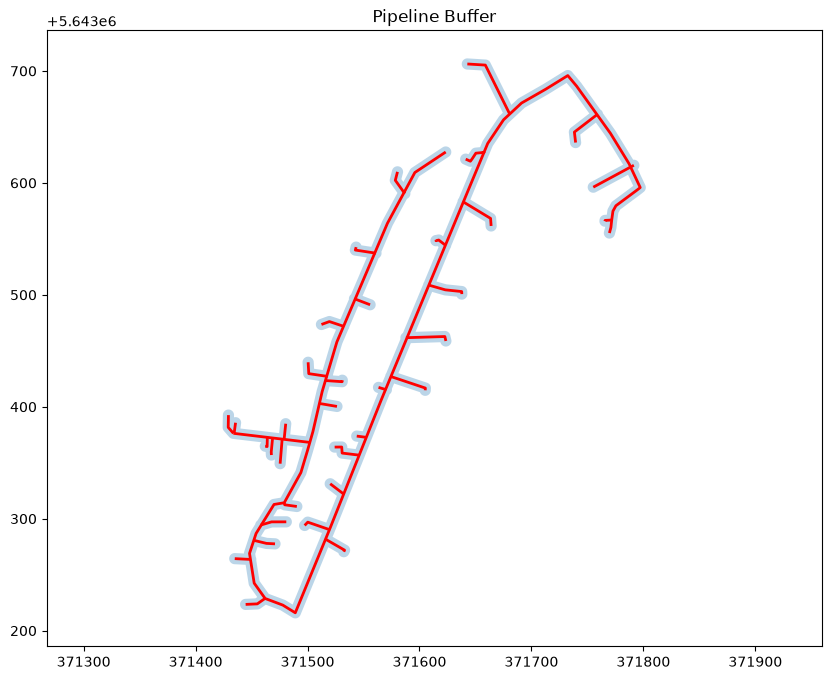

In [ ]:
# plot pipeline buffer

fig, ax = plt.subplots(figsize=(10,8))


pipelines.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="Pipeline"
)


gpd.GeoSeries(
    pipeline_buffer_union,
    crs=target_crs
).plot(
    ax=ax,
    alpha=0.3,
    label="5m buffer"
)


plt.axis("equal")
plt.title("Pipeline Buffer")
plt.show()

In [ ]:


las_path = "../data/pointclouds/20 kmh.las"

with laspy.open(las_path) as f:

    las_bounds = box(
        f.header.mins[0],
        f.header.mins[1],
        f.header.maxs[0],
        f.header.maxs[1]
    )

print(las_bounds)

POLYGON ((371865.88399999996 5643122.299, 371865.88399999996 5643779.899, 371353.963 5643779.899, 371353.963 5643122.299, 371865.88399999996 5643122.299))


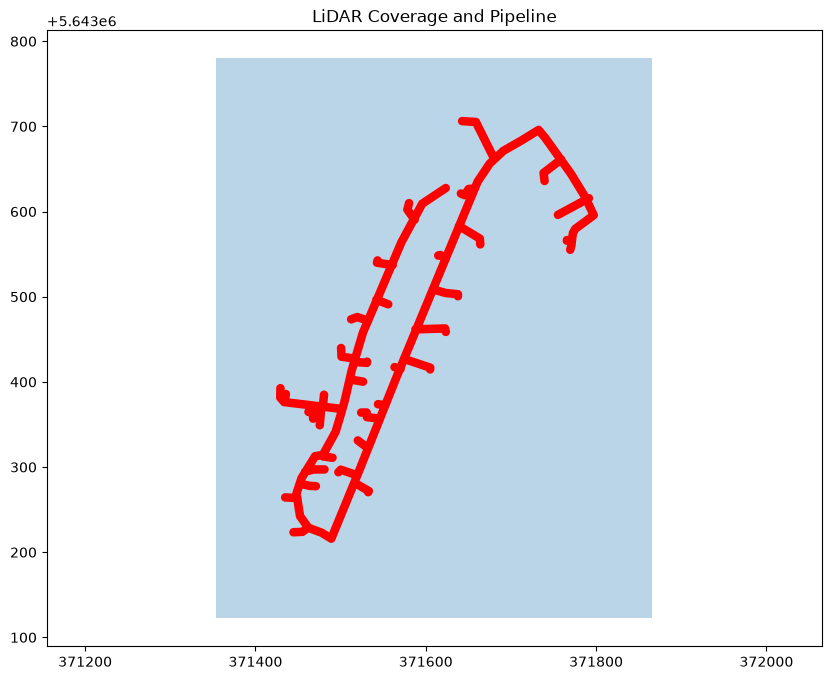

In [ ]:
# plot lidar coverage and pipeline

las_area = gpd.GeoDataFrame(
    geometry=[las_bounds],
    crs=target_crs
)


fig, ax = plt.subplots(figsize=(10,8))


las_area.plot(
    ax=ax,
    alpha=0.3
)


gpd.GeoSeries(
    pipeline_buffer_union,
    crs=target_crs
).plot(
    ax=ax,
    color="red"
)


plt.axis("equal")
plt.title("LiDAR Coverage and Pipeline")
plt.show()

In [ ]:
# function for extract_points_near_pipeline


def extract_points_near_pipeline(
        las_path,
        pipeline_geometry,
        chunk_size=5000000):

    selected_points = []

    with laspy.open(las_path) as las_file:

        for i, chunk in enumerate(las_file.chunk_iterator(chunk_size)):

            print("Processing chunk:", i)

            x = np.array(chunk.x)
            y = np.array(chunk.y)
            z = np.array(chunk.z)

            geometry = [
                Point(px, py)
                for px, py in zip(x, y)
            ]

            points_gdf = gpd.GeoSeries(
                geometry,
                crs="EPSG:32632"
            )

            mask = points_gdf.within(
                pipeline_geometry
            ).values


            if np.any(mask):

                selected = np.column_stack(
                    (
                        x[mask],
                        y[mask],
                        z[mask]
                    )
                )

                selected_points.append(selected)


    if len(selected_points) == 0:
        return np.empty((0,3))


    return np.vstack(selected_points)

In [ ]:
# call the function for extract_points_near_pipeline

pipeline_points = extract_points_near_pipeline(
    las_path,
    pipeline_buffer_union
)


print(
    "Extracted points:",
    pipeline_points.shape
)

Processing chunk: 0
Processing chunk: 1
Processing chunk: 2
Processing chunk: 3
Processing chunk: 4
Processing chunk: 5
Processing chunk: 6
Processing chunk: 7
Processing chunk: 8
Processing chunk: 9
Processing chunk: 10
Processing chunk: 11
Processing chunk: 12
Processing chunk: 13
Processing chunk: 14
Processing chunk: 15
Processing chunk: 16
Processing chunk: 17
Processing chunk: 18
Processing chunk: 19
Processing chunk: 20
Processing chunk: 21
Processing chunk: 22
Processing chunk: 23
Processing chunk: 24
Processing chunk: 25
Processing chunk: 26
Extracted points: (49551690, 3)


In [12]:
print(pipeline_points.shape)

(49551690, 3)


In [ ]:
# save new point cloud file

input_path = "../data/pointclouds/20 kmh.las"
output_path = "../data/processed/20kmh_pipeline_corridor.las"


# Read original header
with laspy.open(input_path) as src:
    header = src.header.copy()


# Create new LAS
new_las = laspy.LasData(header)


# Remove old points
new_las.points = laspy.ScaleAwarePointRecord.zeros(
    len(pipeline_points),
    header=header
)


# Add processed points
new_las.x = pipeline_points[:,0]
new_las.y = pipeline_points[:,1]
new_las.z = pipeline_points[:,2]


# Save
new_las.write(output_path)


print("Saved:", output_path)

Saved: ../data/processed/20kmh_pipeline_corridor_ls.las


In [3]:
check = laspy.read(
    "../data/processed/20kmh_pipeline_corridor_ls.las"
)

print("Points:", len(check.points))
print("CRS:", check.header.parse_crs())

Points: 49551690
CRS: EPSG:32632


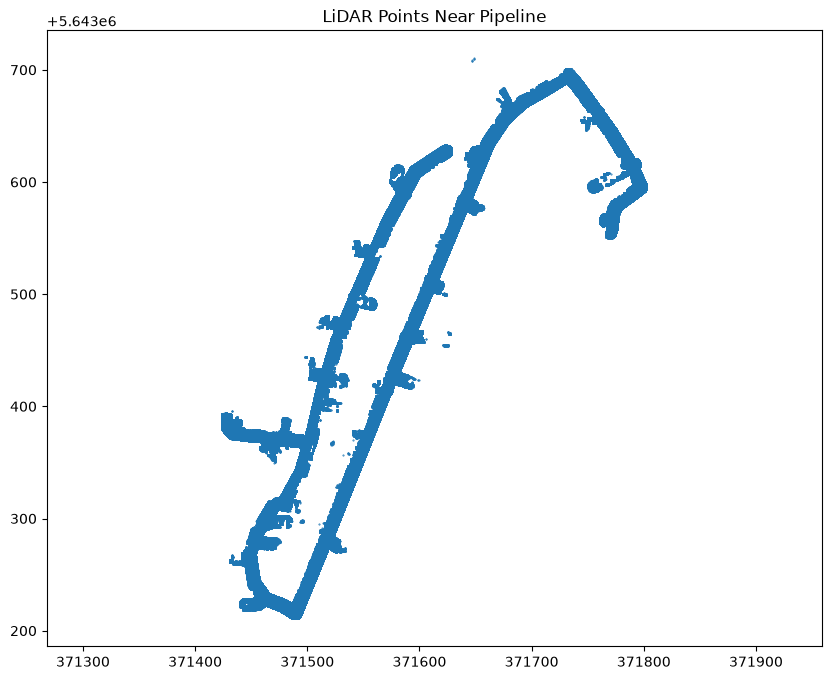

In [15]:
plt.figure(figsize=(10,8))


plt.scatter(
    pipeline_points[:,0],
    pipeline_points[:,1],
    s=0.2
)


plt.axis("equal")
plt.title("LiDAR Points Near Pipeline")
plt.show()

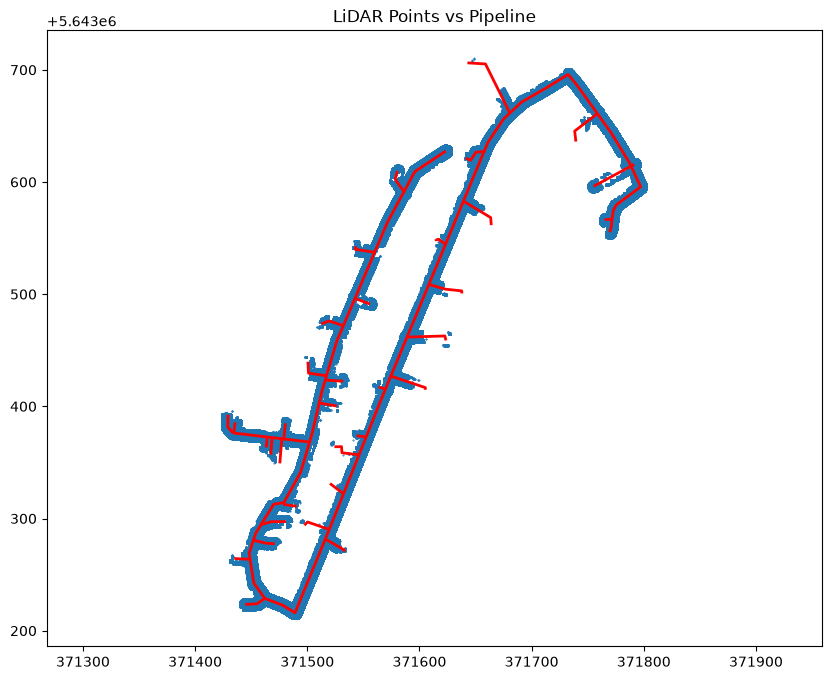

In [ ]:
# plot lidar points vs pipeline

fig, ax = plt.subplots(figsize=(10,8))

ax.scatter(
    pipeline_points[:,0],
    pipeline_points[:,1],
    s=0.2,
    label="LiDAR points"
)


pipelines.plot(
    ax=ax,
    color="red",
    linewidth=2
)


plt.axis("equal")
plt.title("LiDAR Points vs Pipeline")
plt.show()